In [2]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [3]:
# DISPLAY DATA

def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)
        

Text(0.5, 1.0, 'M13 G-band blob model')

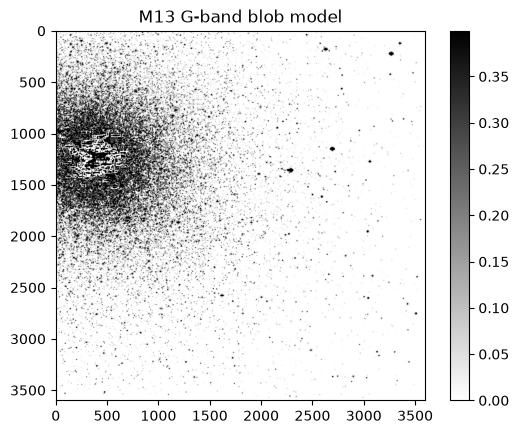

In [22]:
#make the figure
plt.figure()

#read in the data and header
data,headerM13g_blob = fits.getdata('/home/m724p633/ASTR596/Data/legacysurvey-2502p365-blobmodel-g.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 G-band blob model")

In [23]:
M13g_blob = WCS(headerM13g_blob)
print(M13g_blob)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 250.293103448276 36.5
CRPIX : 1800.5 1800.5
CD1_1 CD1_2  : -7.27777777777778e-05 0.0
CD2_1 CD2_2  : 0.0 7.27777777777778e-05
NAXIS : 3600  3600


Text(0.5, 1.0, 'M13 R-band blob model')

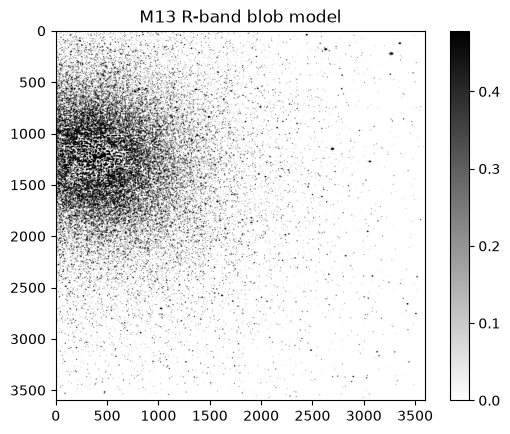

In [15]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('/home/m724p633/ASTR596/Data/legacysurvey-2502p365-blobmodel-r.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 R-band blob model")

Text(0.5, 1.0, 'M13 G-band image')

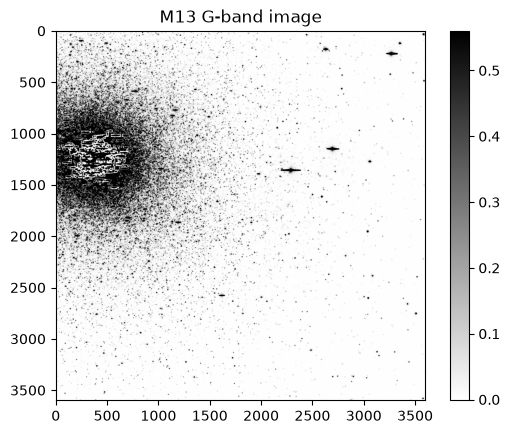

In [17]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('/home/m724p633/ASTR596/Data/legacysurvey-2502p365-image-g.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 G-band image")

Text(0.5, 1.0, 'M13 R-band image')

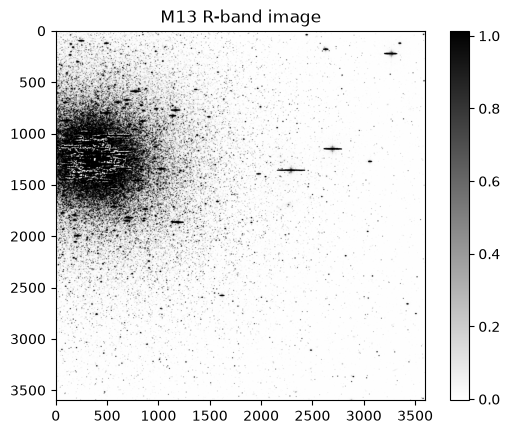

In [4]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('/home/m724p633/ASTR596/Data/legacysurvey-2502p365-image-r.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 R-band image")